# Data Augmentation on a toy problem

**The story.** We only see a small **subset** of a true function — and this subset **lies to us**: the points are noisy and some of the labels are wrong. A flexible model trusts every point and learns the function the subset *suggests*, not the true one. Data augmentation (DA) is a way to tell the model not to trust each point on its own.

We look at DA through the three lenses of the lesson:

1. **Vicinal Risk Minimization (VRM)** — train on a neighbourhood $\nu(\cdot \mid x)$ around the examples, not on the points alone. Two vicinities: a **Gaussian Mixture Model** per class, and **mixup**.
2. **Regularization** — augmented samples act like noise injection and smooth the decision boundary.
3. **Invariance** — if a transformation $T$ should not change the label, training on $(T(x), y)$ teaches the model to ignore what $T$ changes.

Two models with very different inductive biases:
- **Polynomial model** — degree‑9 polynomial features + (almost un‑regularized) logistic regression;
- **Neural network** — a 2×64 ReLU MLP.

Every result is a comparison of the **same model, trained on the same labels, without and with augmentation**.

In [22]:
import os, logging, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse, FancyBboxPatch, Circle
from IPython.display import Image, Markdown, display

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.mixture import GaussianMixture
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")                                   # convergence warnings of the un-regularized models
os.environ["PYTHONWARNINGS"] = "ignore"                             # same for the parallel workers
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
os.makedirs("animations", exist_ok=True)

N_TRAIN, NOISE, FLIP = 100, 0.2, 0.1

### Visual style
All figures share one dark "neon" style: each model has its colour, class 0 is drawn in white and class 1 in the model's colour, the region the model assigns to class 1 glows in the same colour (brighter = more confident).

In [23]:
BG, PANEL, GRIDC, TXT, DIM = "#07090d", "#0e1118", "#1f2633", "#e6e9ef", "#7c8597"
MONO = ["Menlo", "DejaVu Sans Mono", "monospace"]
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "figure.facecolor": BG, "savefig.facecolor": BG, "axes.facecolor": PANEL,
    "axes.edgecolor": GRIDC, "axes.labelcolor": DIM, "xtick.color": DIM, "ytick.color": DIM,
    "text.color": TXT, "axes.titlecolor": TXT, "legend.labelcolor": TXT, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100,
})
COL = {"poly": "#4fa3ff", "nn": "#b794f4"}                          # model colours
MCOL = {"none": "#7c8597", "gmm": "#f6ad55", "mixup": "#f687b3"}    # method colours (charts)
TRUE_C = "#68d391"                                                  # the true boundary

class Panel:
    """A rounded neon card with a header (title, formula, tag), a square plot and a footer."""
    def __init__(self, fig, x, y, w, h, color, W, H, aspect=1.0):
        self.fig, self.color = fig, color
        fig.patches.append(FancyBboxPatch((x / W, y / H), w / W, h / H, transform=fig.transFigure,
                           boxstyle="round,pad=0,rounding_size=0.012", fc=PANEL, ec=color, lw=1.4, zorder=-10))
        aw = w - 0.3; ah = aw * aspect                                 # plot area follows the data aspect ratio
        if ah > h - 1.45: ah = h - 1.45; aw = ah / aspect
        self.ax = fig.add_axes([(x + (w - aw) / 2) / W, (y + 0.5 + (h - 1.45 - ah) / 2) / H, aw / W, ah / H])
        kw = dict(transform=fig.transFigure, va="center")
        self.title = fig.text((x + 0.16) / W, (y + h - 0.3) / H, "", color=color, fontsize=13, fontweight="bold", **kw)
        self.formula = fig.text((x + 0.16) / W, (y + h - 0.66) / H, "", color=TXT, fontsize=11, family=MONO, **kw)
        self.tag = fig.text((x + w - 0.16) / W, (y + h - 0.66) / H, "", color=color, fontsize=11, family=MONO, ha="right",
                            bbox=dict(boxstyle="round,pad=0.25", fc=BG, ec=color, lw=1), **kw)
        self.foot_l = fig.text((x + 0.16) / W, (y + 0.24) / H, "", color=TXT, fontsize=12, family=MONO, **kw)
        self.foot_r = fig.text((x + w - 0.16) / W, (y + 0.24) / H, "", color=DIM, fontsize=10.5, ha="right", **kw)
        if not color: self.tag.set_visible(False)

    def set(self, title=None, formula=None, tag=None, foot_l=None, foot_r=None):
        for obj, v in [(self.title, title), (self.formula, formula), (self.tag, tag), (self.foot_l, foot_l), (self.foot_r, foot_r)]:
            if v is not None: obj.set_text(v)
        self.tag.set_visible(bool(self.tag.get_text()))

def panel_grid(nrows, ncols, colors, pw=4.3, ph=None, aspect=1.0, title=None, subtitle=None, extra_right=0.0, gap=0.28):
    """Figure with nrows x ncols neon panels. colors: one colour per panel (row-major). Returns fig, panels, (W, H)."""
    top = (0.95 if subtitle else 0.7) if title else gap
    if ph is None: ph = (pw - 0.3) * aspect + 1.45
    W = ncols * pw + (ncols + 1) * gap + extra_right
    H = nrows * ph + (nrows + 1) * gap + top - gap
    fig = plt.figure(figsize=(W, H))
    if title: fig.text(0.5, 1 - 0.38 / H, title, ha="center", va="center", fontsize=18, fontweight="bold")
    if subtitle: fig.text(0.5, 1 - 0.72 / H, subtitle, ha="center", va="center", fontsize=11, color=DIM)
    panels = []
    for r in range(nrows):
        for c in range(ncols):
            x = gap + c * (pw + gap); y = H - top - (r + 1) * ph - r * gap
            panels.append(Panel(fig, x, y, pw, ph, colors[r * ncols + c], W, H, aspect))
    return fig, panels, (W, H)

def neon_chart(ax, title, xlabel="", ylabel=""):
    ax.set_facecolor(PANEL); ax.set_axisbelow(True); ax.grid(color=GRIDC, lw=0.6)
    for s in ax.spines.values(): s.set_color(GRIDC)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

def region_cmap(color):
    return LinearSegmentedColormap.from_list("r", [PANEL, PANEL, color], N=256)

In [24]:
display(Markdown(f"""## 1. The true function and the subset we get to see

**True function.** Two interleaved half‑moons. The **oracle** gives the true label of any point in the plane: the moon it is closest to. Its decision boundary (green, dashed) is the best any classifier could do.

**The subset.** We get only **{N_TRAIN} labelled points**, sampled with noise (σ = {NOISE}) and with **{FLIP:.0%} of the labels flipped** — annotation errors. Some points end up on the wrong side of the true boundary: we mark them with ✕. They are the lies in our subset.

The test set is labelled by the oracle: we measure how close a model gets to the **true** function, not to the noise."""))

## 1. The true function and the subset we get to see

**True function.** Two interleaved half‑moons. The **oracle** gives the true label of any point in the plane: the moon it is closest to. Its decision boundary (green, dashed) is the best any classifier could do.

**The subset.** We get only **100 labelled points**, sampled with noise (σ = 0.2) and with **10% of the labels flipped** — annotation errors. Some points end up on the wrong side of the true boundary: we mark them with ✕. They are the lies in our subset.

The test set is labelled by the oracle: we measure how close a model gets to the **true** function, not to the noise.

In [25]:
_t = np.linspace(0, np.pi, 1500)
ARC0, ARC1 = np.c_[np.cos(_t), np.sin(_t)], np.c_[1 - np.cos(_t), 0.5 - np.sin(_t)]

def oracle(X):
    """True label of any point: the closest moon (computed in chunks to save memory)."""
    out = []
    for i in range(0, len(X), 2000):
        x = X[i:i + 2000]
        d0 = ((x[:, None] - ARC0[None]) ** 2).sum(-1).min(1); d1 = ((x[:, None] - ARC1[None]) ** 2).sum(-1).min(1)
        out.append((d1 < d0).astype(int))
    return np.concatenate(out)

def make_subset(seed, n=N_TRAIN, noise=NOISE, flip=FLIP):
    rng = np.random.default_rng(seed)
    y = rng.integers(0, 2, n); t = rng.uniform(0, np.pi, n)
    X = np.where(y[:, None] == 0, np.c_[np.cos(t), np.sin(t)], np.c_[1 - np.cos(t), 0.5 - np.sin(t)]) + rng.normal(0, noise, (n, 2))
    y = np.where(rng.random(n) < flip, 1 - y, y)                       # annotation errors
    return X, y

rng = np.random.default_rng(999)
_y = rng.integers(0, 2, 3000); _tt = rng.uniform(0, np.pi, 3000)
X_te = np.where(_y[:, None] == 0, np.c_[np.cos(_tt), np.sin(_tt)], np.c_[1 - np.cos(_tt), 0.5 - np.sin(_tt)]) + rng.normal(0, NOISE, (3000, 2))
y_te = oracle(X_te)

XL, YL = (-1.55, 2.55), (-1.25, 1.75)
_gx, _gy = np.meshgrid(np.linspace(*XL, 230), np.linspace(*YL, 230))
GRID = np.c_[_gx.ravel(), _gy.ravel()]
TRUE_Z = oracle(GRID).reshape(_gx.shape)
ASP = (YL[1] - YL[0]) / (XL[1] - XL[0])                                # height / width of the plotted region

def draw_points(ax, X, y, color, s=30):
    wrong = oracle(X) != y
    ax.scatter(*X[(y == 0) & ~wrong].T, s=s, c="white", edgecolors=BG, linewidths=0.6, zorder=4)
    ax.scatter(*X[(y == 1) & ~wrong].T, s=s, c=color, edgecolors=BG, linewidths=0.6, zorder=4)
    ax.scatter(*X[(y == 0) & wrong].T, s=s * 2.6, c="white", marker="X", edgecolors=BG, linewidths=0.6, zorder=5)
    ax.scatter(*X[(y == 1) & wrong].T, s=s * 2.6, c=color, marker="X", edgecolors=BG, linewidths=0.6, zorder=5)

def draw_true(ax):
    ax.contour(_gx, _gy, TRUE_Z, levels=[0.5], colors=[TRUE_C], linewidths=1.3, linestyles=[(0, (4, 3))], alpha=0.9)

def draw_model(ax, model, color, X=None, y=None, X_aug=None, y_aug=None, show_true=True):
    p = model.predict_proba(GRID)[:, 1].reshape(_gx.shape)
    ax.imshow(p, extent=(*XL, *YL), origin="lower", cmap=region_cmap(color), vmin=0, vmax=1, alpha=0.6, interpolation="bilinear", aspect="auto")
    for lw, a in [(7, 0.08), (4, 0.18), (1.6, 1.0)]:                   # glowing boundary
        ax.contour(_gx, _gy, p, levels=[0.5], colors=[color], linewidths=lw, alpha=a)
    if show_true: draw_true(ax)
    if X_aug is not None:
        ax.scatter(*X_aug[y_aug == 0].T, s=6, c="white", alpha=0.35, lw=0, zorder=2)
        ax.scatter(*X_aug[y_aug == 1].T, s=6, c=color, alpha=0.5, lw=0, zorder=2)
    if X is not None: draw_points(ax, X, y, color)
    clean(ax)

def clean(ax):
    ax.set(xlim=XL, ylim=YL, xticks=[], yticks=[], aspect="equal")
    for s in ax.spines.values(): s.set_visible(False)

## 2. Models and evaluation protocol

- Accuracy changes a lot from one subset to another, so every number is averaged over **20 different subsets** (`EVAL_SEEDS`), and we also report the **win rate**: in how many subsets augmentation beats no augmentation.
- The hyper‑parameters of the augmentations (K for the GMM, α for mixup) are chosen on **20 other subsets** (`TUNE_SEEDS`), so the final comparison is not tuned on the subsets it is evaluated on.
- Figures show one **representative subset**: the most typical of the 20 (baseline accuracy and gains closest to the averages), not the most favourable one.

In [26]:
def poly_model():
    return make_pipeline(PolynomialFeatures(degree=9), StandardScaler(), LogisticRegression(C=1e4, max_iter=20000))

def nn_model(seed=0):
    return MLPClassifier(hidden_layer_sizes=(32, 32), alpha=1e-5, max_iter=3000, tol=1e-6, random_state=seed)

MODELS = {"poly": dict(name="Polynomial", formula="p = σ(w·φ₉(x) + b)", make=poly_model),
          "nn":   dict(name="Neural net", formula="2 layers × 32, ReLU", make=nn_model)}
EVAL_SEEDS, TUNE_SEEDS = list(range(20)), list(range(100, 120))

def input_gradient_norm(model, X, eps=1e-3):
    """Mean ‖∇ₓ p(y=1|x)‖ over X (finite differences): lower = smoother boundary."""
    g = [(model.predict_proba(X + e)[:, 1] - model.predict_proba(X - e)[:, 1]) / (2 * eps) for e in np.eye(2) * eps]
    return np.linalg.norm(np.c_[g[0], g[1]], axis=1).mean()

def _eval_one(s, augment, kw):
    warnings.filterwarnings("ignore")                              # also inside the parallel workers
    X, y = make_subset(s); out = {}; agree = None
    if augment is not None:
        Xa, ya = augment(X, y, np.random.default_rng(1000 + s), **kw)
        agree = (oracle(Xa) == ya).mean(); X_fit, y_fit = np.vstack([X, Xa]), np.r_[y, ya]
    else:
        X_fit, y_fit = X, y
    for mk, spec in MODELS.items():
        m = spec["make"]().fit(X_fit, y_fit)
        out[mk] = (m.score(X_te, y_te), m.score(X, y), input_gradient_norm(m, X_te))
    return out, agree

def evaluate(augment=None, seeds=EVAL_SEEDS, **kw):
    """Per-subset test acc, train acc, boundary sharpness of each model (subsets run in parallel on all cores)."""
    outs = Parallel(n_jobs=-1)(delayed(_eval_one)(s, augment, kw) for s in seeds)
    res = {mk: {k: np.array([o[0][mk][j] for o in outs]) for j, k in enumerate(["test", "train", "grad"])} for mk in MODELS}
    res["agree"] = np.mean([o[1] for o in outs]) if augment is not None else None
    return res

**The two augmentations** (explained in §3 and §4). Each one takes the labelled subset and returns extra samples with labels.

In [27]:
def gmm_vicinity(X, y, rng, K=2, m=20):
    Xs, ys = [], []
    for c in (0, 1):
        Xc = X[y == c]
        g = GaussianMixture(min(K, len(Xc)), covariance_type="full", reg_covar=1e-3, random_state=int(rng.integers(1e6))).fit(Xc)
        Xa, _ = g.sample(len(Xc) * m); Xs.append(Xa); ys.append(np.full(len(Xa), c))
    return np.vstack(Xs), np.concatenate(ys)

def mixup(X, y, rng, alpha=1.0, m=20):
    i = rng.integers(0, len(X), len(X) * m); j = rng.integers(0, len(X), len(X) * m)
    lam = rng.beta(alpha, alpha, len(i))
    return lam[:, None] * X[i] + (1 - lam[:, None]) * X[j], np.where(rng.random(len(i)) < lam, y[i], y[j])

**Tuning, evaluation and choice of the representative subset.** This is the heavy cell (a few minutes): K and α are chosen on the tuning subsets, then all three methods are evaluated on the 20 evaluation subsets. The representative subset is the **most typical** one: its accuracy without DA and the gain of each augmentation are the closest to the averages over the 20 subsets.

In [28]:
KS = [1, 2, 3, 4, 6, 10]
SWEEP_K = {K: evaluate(gmm_vicinity, seeds=TUNE_SEEDS, K=K) for K in KS}
BASE_T = evaluate(seeds=TUNE_SEEDS)
K_BEST = max(KS, key=lambda K: sum(SWEEP_K[K][mk]["test"].mean() for mk in MODELS))
ALPHAS = [0.1, 0.2, 0.5, 1.0, 2.0, 4.0]
SWEEP_A = {a: evaluate(mixup, seeds=TUNE_SEEDS, alpha=a) for a in ALPHAS}
A_BEST = max(ALPHAS, key=lambda a: sum(SWEEP_A[a][mk]["test"].mean() for mk in MODELS))

AUG = {"none": (None, {}), "gmm": (gmm_vicinity, dict(K=K_BEST)), "mixup": (mixup, dict(alpha=A_BEST))}
LABEL = {"none": "no augmentation", "gmm": f"GMM (K = {K_BEST})", "mixup": f"mixup (α = {A_BEST})"}
TAG = {"none": "no DA", "gmm": f"K = {K_BEST}", "mixup": f"α = {A_BEST}"}
BASE = evaluate()
RES = {"none": BASE, "gmm": evaluate(gmm_vicinity, K=K_BEST), "mixup": evaluate(mixup, alpha=A_BEST)}

F = np.column_stack([BASE[mk]["test"] for mk in MODELS] +                                   # accuracy without DA
                    [RES[ak][mk]["test"] - BASE[mk]["test"] for ak in ("gmm", "mixup") for mk in MODELS])  # gain of each DA
REP = EVAL_SEEDS[int(np.argmin(((F - F.mean(0)) ** 2).sum(1)))]
X_tr, y_tr = make_subset(REP)
print(f"chosen K = {K_BEST}, chosen α = {A_BEST}, representative subset: seed {REP}")
print(f"labels in the representative subset that agree with the true function: {(oracle(X_tr) == y_tr).mean():.0%}")
for mk in MODELS:
    print(f"{MODELS[mk]['name']:12s} no augmentation: train acc {BASE[mk]['train'].mean():.0%} · test acc {BASE[mk]['test'].mean():.3f} ± {BASE[mk]['test'].std():.3f}")

chosen K = 2, chosen α = 0.5, representative subset: seed 5
labels in the representative subset that agree with the true function: 83%
Polynomial   no augmentation: train acc 96% · test acc 0.841 ± 0.044
Neural net   no augmentation: train acc 97% · test acc 0.879 ± 0.041


### The true function vs what the subset suggests

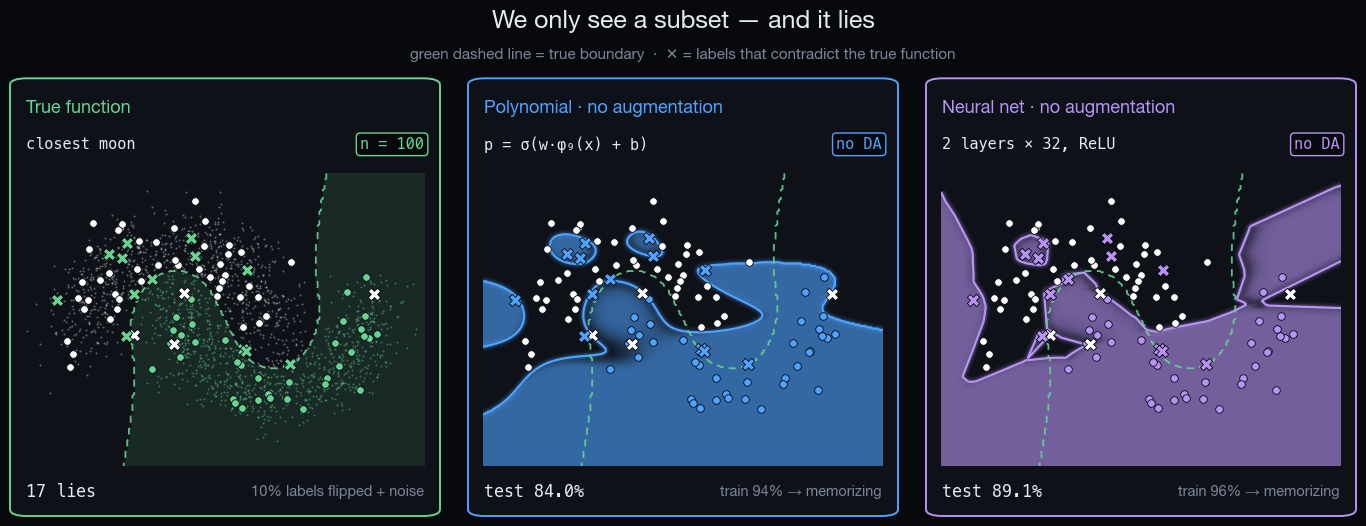

In [29]:
fig, P, _ = panel_grid(1, 3, [TRUE_C, COL["poly"], COL["nn"]], aspect=ASP, title="We only see a subset — and it lies",
                       subtitle="green dashed line = true boundary  ·  ✕ = labels that contradict the true function")
ax = P[0].ax
ax.imshow(TRUE_Z, extent=(*XL, *YL), origin="lower", cmap=region_cmap(TRUE_C), vmin=0, vmax=1.6, alpha=0.5, aspect="auto")
draw_true(ax); ax.scatter(*X_te[y_te == 0][:900].T, s=2, c="white", alpha=0.35, lw=0); ax.scatter(*X_te[y_te == 1][:900].T, s=2, c=TRUE_C, alpha=0.45, lw=0)
draw_points(ax, X_tr, y_tr, TRUE_C); clean(ax)
P[0].set(title="True function", formula="closest moon", tag=f"n = {N_TRAIN}",
         foot_l=f"{(oracle(X_tr) != y_tr).sum()} lies", foot_r=f"{FLIP:.0%} labels flipped + noise")
for p_, mk in zip(P[1:], MODELS):
    m = MODELS[mk]["make"]().fit(X_tr, y_tr); draw_model(p_.ax, m, COL[mk], X_tr, y_tr)
    p_.set(title=f"{MODELS[mk]['name']} · no augmentation", formula=MODELS[mk]["formula"], tag="no DA",
           foot_l=f"test {m.score(X_te, y_te):.1%}", foot_r=f"train {m.score(X_tr, y_tr):.0%} → memorizing")
plt.show()

Both models reach (almost) 100 % training accuracy: they bend the boundary around every ✕ and learn the function the subset suggests. The question is how to make them **stop believing isolated points**.

## 3. Property 1 — VRM with a Gaussian Mixture Model

Empirical Risk Minimization puts a Dirac delta on each training point: $\hat P(x\mid y) = \frac1{n_y}\sum_{i:\,y_i=y}\delta(x-x_i)$.
VRM replaces the deltas with a smooth **vicinity distribution** and trains on samples drawn from it.

**Vicinity = a GMM fitted on each class**, in the 2‑D feature space:
$$\nu(\tilde x\mid y) = \sum_{k=1}^{K}\pi_k^{(y)}\,\mathcal N\big(\tilde x;\ \mu_k^{(y)},\Sigma_k^{(y)}\big),\qquad \mu_k\in\mathbb R^2,\ \Sigma_k\in\mathbb R^{2\times2}$$
fitted with EM; we then **sample** $m = 20$ new points per original point and give them the class label.

- $K$ (number of components) is the knob. It is not the number of dimensions — every Gaussian lives in the same 2‑D space.
- With $K = n_y$ components centred on the points and a fixed $\Sigma=\sigma^2 I$, the GMM is plain Gaussian jitter around each point (the Parzen vicinity of the original VRM paper).
- **Why it fights the lies:** with few components, a mislabelled point cannot get a Gaussian of its own. It is absorbed by the bulk of its (wrong) class, so the samples follow where *most* of the class is, not where the isolated point is.

In [30]:
def draw_gmm(ax, g, color):
    for mu, S in zip(g.means_, g.covariances_):
        vals, vecs = np.linalg.eigh(S)
        ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1])); w, h = 4 * np.sqrt(vals[::-1])
        for lw, a in [(5, 0.12), (1.5, 1.0)]:
            ax.add_patch(Ellipse(mu, w, h, angle=ang, fill=False, color=color, lw=lw, alpha=a))
        ax.plot(*mu, "+", color=color, ms=9, mew=1.5)

### 3a. The fitted GMMs (2σ ellipses) and their samples

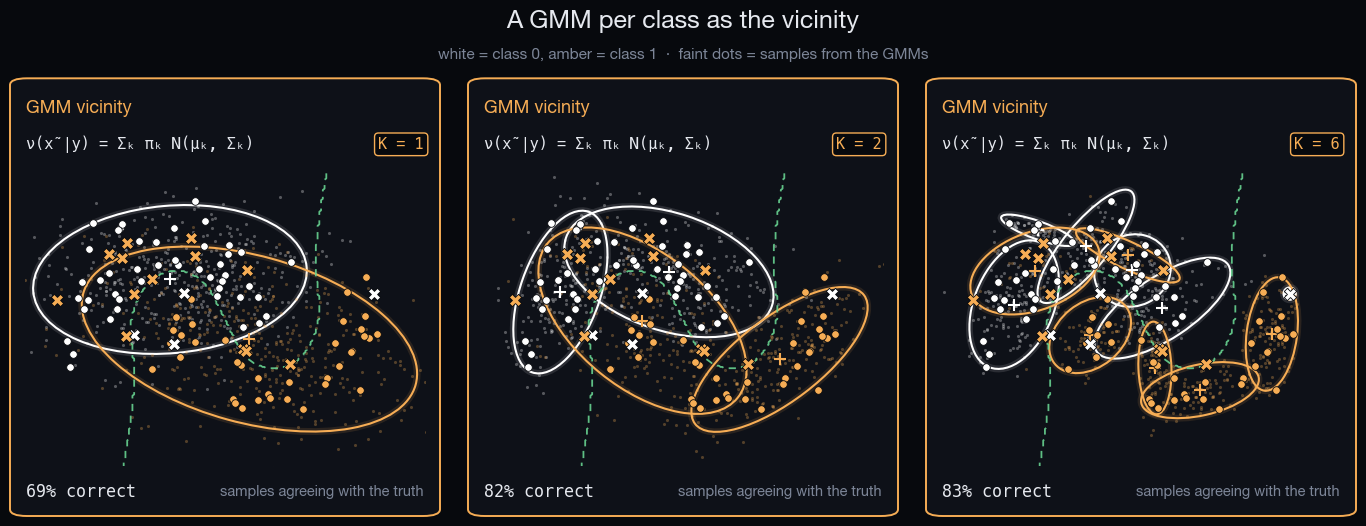

this subset: 83% of the original labels agree with the true function
average over the 20 subsets: original labels 86%, GMM samples (K = 2) 84%, mixup samples 75%


In [31]:
GMM_SHOW = [1, 2, 6]
fig, P, _ = panel_grid(1, 3, [MCOL["gmm"]] * 3, aspect=ASP, title="A GMM per class as the vicinity",
                       subtitle="white = class 0, amber = class 1  ·  faint dots = samples from the GMMs")
for p_, K in zip(P, GMM_SHOW):
    ax = p_.ax; ax.set_facecolor(PANEL); draw_true(ax)
    for c, col in [(0, "white"), (1, MCOL["gmm"])]:
        g = GaussianMixture(K, covariance_type="full", reg_covar=1e-3, random_state=0).fit(X_tr[y_tr == c])
        Xs, _ = g.sample(400); ax.scatter(*Xs.T, s=5, c=col, alpha=0.3, lw=0); draw_gmm(ax, g, col)
    draw_points(ax, X_tr, y_tr, MCOL["gmm"]); clean(ax)
    Xa, ya = gmm_vicinity(X_tr, y_tr, np.random.default_rng(1000 + REP), K=K)
    p_.set(title="GMM vicinity", formula="ν(x̃|y) = Σₖ πₖ N(μₖ, Σₖ)", tag=f"K = {K}",
           foot_l=f"{(oracle(Xa) == ya).mean():.0%} correct", foot_r="samples agreeing with the truth")
plt.show()
print(f"this subset: {(oracle(X_tr) == y_tr).mean():.0%} of the original labels agree with the true function")
print(f"average over the 20 subsets: original labels {np.mean([(oracle(make_subset(s)[0]) == make_subset(s)[1]).mean() for s in EVAL_SEEDS]):.0%}, "
      f"GMM samples (K = {K_BEST}) {RES['gmm']['agree']:.0%}, mixup samples {RES['mixup']['agree']:.0%}")

Note what the GMM does **not** do: it does not fix the wrong labels — about the same share of samples agrees with the true function as in the original subset (printed above). What it changes is the **shape** of the labelled data: with $K = 1$–$2$ each class becomes a smooth blob, and an isolated ✕ can no longer pull the boundary around itself. With $K = 6$ the components start wrapping small groups of points — including the lies.

### 3b. How many components? (tuning subsets)

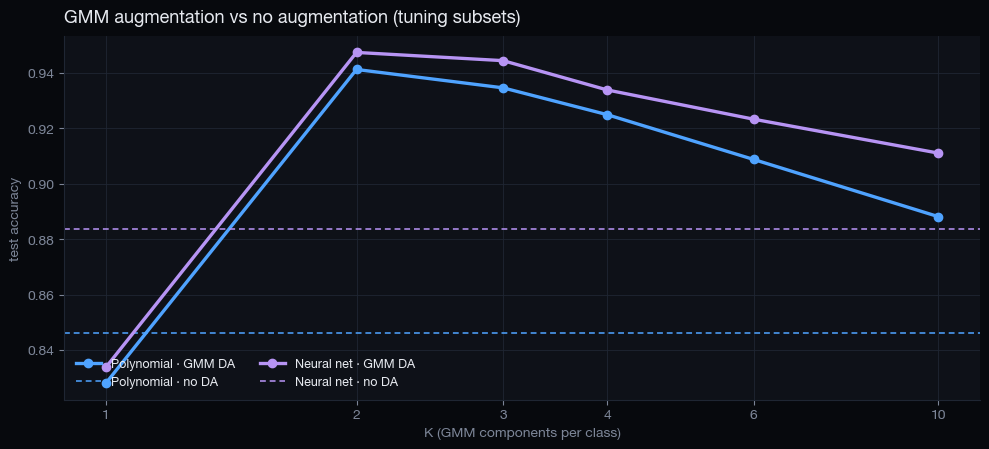

In [32]:

fig, ax = plt.subplots(figsize=(10, 4.6)); neon_chart(ax, "GMM augmentation vs no augmentation (tuning subsets)", "K (GMM components per class)", "test accuracy")
for mk in MODELS:
    mu = np.array([SWEEP_K[K][mk]["test"].mean() for K in KS])
    ax.plot(KS, mu, "o-", color=COL[mk], lw=2.4, label=f"{MODELS[mk]['name']} · GMM DA")
    ax.axhline(BASE_T[mk]["test"].mean(), color=COL[mk], ls=(0, (3, 2)), lw=1.4, alpha=0.8, label=f"{MODELS[mk]['name']} · no DA")
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.legend(loc="lower left", fontsize=9, ncol=2); plt.tight_layout(); plt.show()

Few components win: the vicinity must be **coarser than the noise**. As $K$ grows, each component hugs fewer points and the GMM starts reproducing the lies.

## 4. Property 1 (bis) — mixup

Mixup draws $\lambda \sim \mathrm{Beta}(\alpha,\alpha)$ and two random training points:
$$\tilde x = \lambda x_i + (1-\lambda)x_j,\qquad \tilde y = \lambda y_i + (1-\lambda) y_j .$$
scikit‑learn models do not accept soft labels, so we **sample** the hard label: $\tilde y = y_i$ with probability $\lambda$. In expectation this is the same cross‑entropy as the soft label.

**Why it fights the lies:** a mislabelled point is mixed with many correctly labelled neighbours, so its wrong label is diluted. Between the two classes, mixup asks the model to change its prediction *linearly* — no sharp detours around single points.

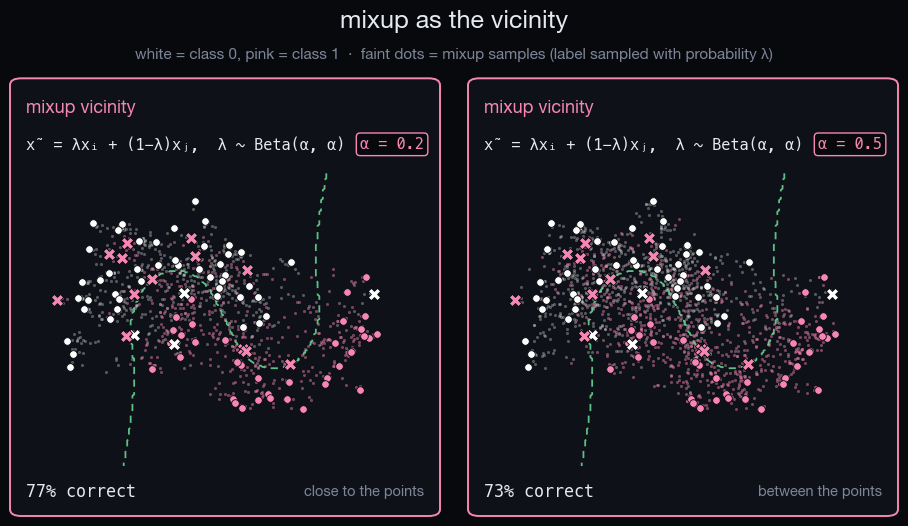

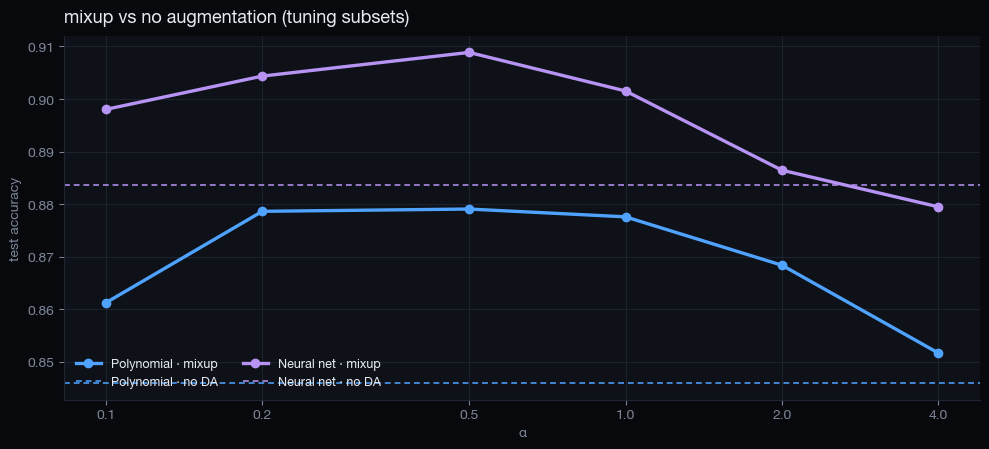

In [33]:

fig, P, _ = panel_grid(1, 2, [MCOL["mixup"]] * 2, aspect=ASP, title="mixup as the vicinity",
                       subtitle="white = class 0, pink = class 1  ·  faint dots = mixup samples (label sampled with probability λ)")
for p_, a in zip(P, [0.2, A_BEST]):
    ax = p_.ax; ax.set_facecolor(PANEL)
    Xa, ya = mixup(X_tr, y_tr, np.random.default_rng(1000 + REP), alpha=a)
    ax.scatter(*Xa[ya == 0].T, s=5, c="white", alpha=0.3, lw=0); ax.scatter(*Xa[ya == 1].T, s=5, c=MCOL["mixup"], alpha=0.45, lw=0)
    draw_true(ax); draw_points(ax, X_tr, y_tr, MCOL["mixup"]); clean(ax)
    p_.set(title="mixup vicinity", formula="x̃ = λxᵢ + (1−λ)xⱼ,  λ ~ Beta(α, α)", tag=f"α = {a}",
           foot_l=f"{(oracle(Xa) == ya).mean():.0%} correct", foot_r="close to the points" if a < 0.5 else "between the points")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.6)); neon_chart(ax, "mixup vs no augmentation (tuning subsets)", "α", "test accuracy")
for mk in MODELS:
    ax.plot(ALPHAS, [SWEEP_A[a][mk]["test"].mean() for a in ALPHAS], "o-", color=COL[mk], lw=2.4, label=f"{MODELS[mk]['name']} · mixup")
    ax.axhline(BASE_T[mk]["test"].mean(), color=COL[mk], ls=(0, (3, 2)), lw=1.4, alpha=0.8, label=f"{MODELS[mk]['name']} · no DA")
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(ALPHAS); ax.set_xticklabels(ALPHAS); ax.legend(fontsize=9, ncol=2, loc="lower left")
plt.tight_layout(); plt.show()

Small α → λ close to 0 or 1 → samples close to the original points (almost no augmentation). Larger α → more interpolation, more dilution of the wrong labels.

## 5. The comparison: no DA vs GMM vs mixup

Hyper‑parameters fixed from the tuning subsets; evaluation on the 20 evaluation subsets.

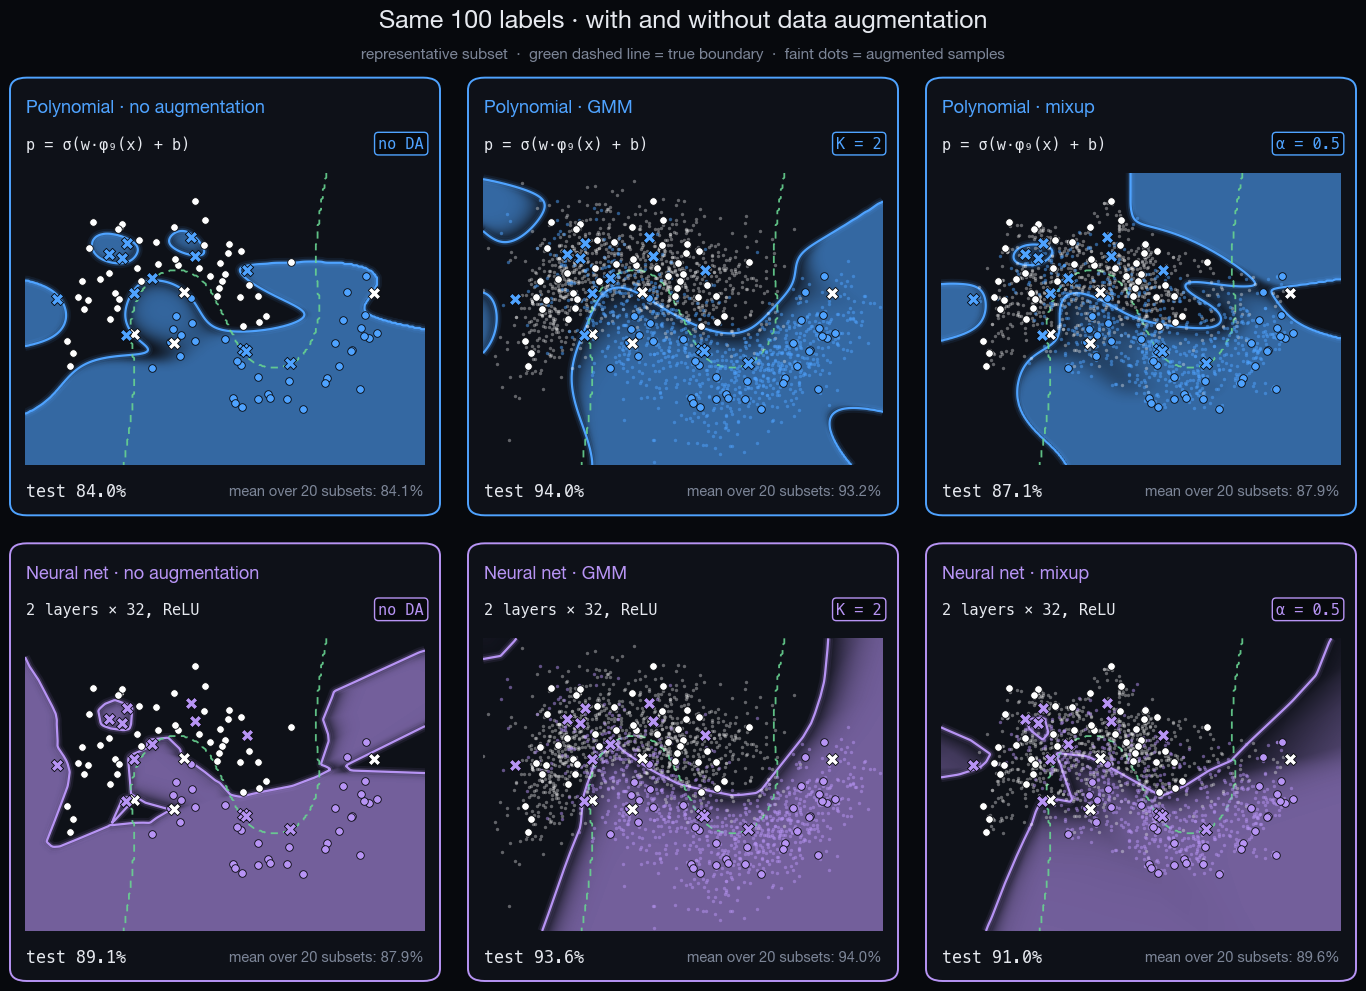

In [34]:

fig, P, _ = panel_grid(2, 3, [COL["poly"]] * 3 + [COL["nn"]] * 3, aspect=ASP, title=f"Same {N_TRAIN} labels · with and without data augmentation",
                       subtitle="representative subset  ·  green dashed line = true boundary  ·  faint dots = augmented samples")
for r, mk in enumerate(MODELS):
    for c, ak in enumerate(AUG):
        f, kw = AUG[ak]; p_ = P[r * 3 + c]
        if f is None: Xa = ya = None; m = MODELS[mk]["make"]().fit(X_tr, y_tr)
        else:
            Xa, ya = f(X_tr, y_tr, np.random.default_rng(1000 + REP), **kw); m = MODELS[mk]["make"]().fit(np.vstack([X_tr, Xa]), np.r_[y_tr, ya])
        draw_model(p_.ax, m, COL[mk], X_tr, y_tr, Xa, ya)
        mean = RES[ak][mk]["test"].mean()
        p_.set(title=f"{MODELS[mk]['name']} · {LABEL[ak].split(' (')[0]}", formula=MODELS[mk]["formula"], tag=TAG[ak],
               foot_l=f"test {m.score(X_te, y_te):.1%}", foot_r=f"mean over {len(EVAL_SEEDS)} subsets: {mean:.1%}")
plt.show()

### Over all 20 subsets
Each dot is one subset; lines connect the same subset across methods.

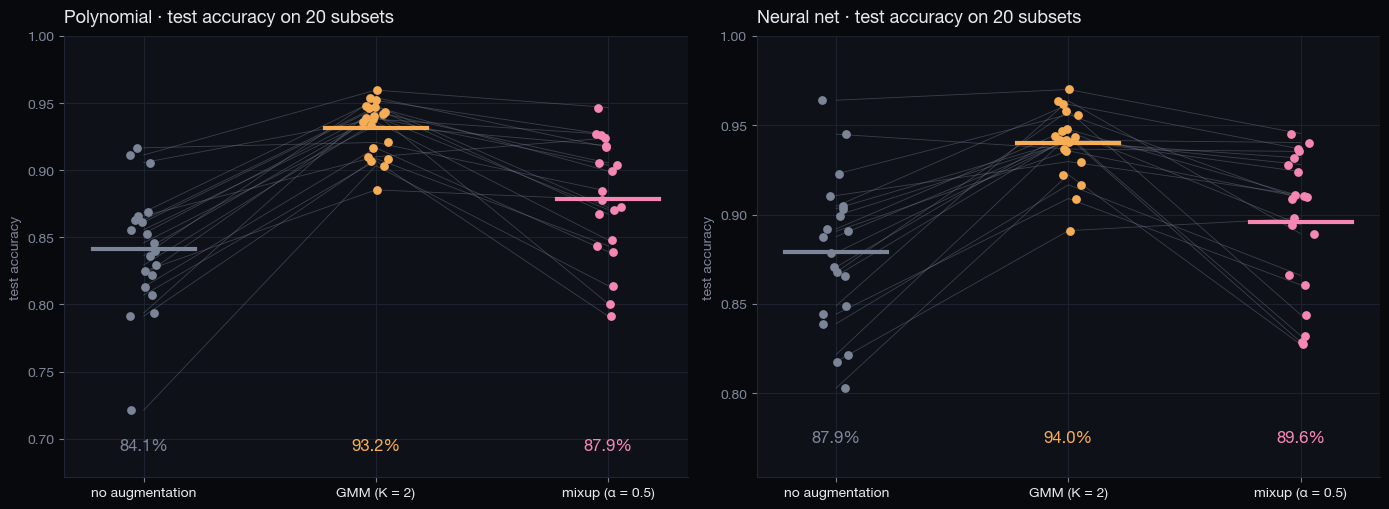

                        no DA                GMM (K = 2)            mixup (α = 0.5)
Polynomial   0.841 ± 0.044     0.932 ± 0.020 (Δ +0.090, wins 100%)   0.879 ± 0.044 (Δ +0.038, wins 85%)
Neural net   0.879 ± 0.041     0.940 ± 0.019 (Δ +0.061, wins 95%)   0.896 ± 0.039 (Δ +0.017, wins 75%)


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, mk in zip(axes, MODELS):
    neon_chart(ax, f"{MODELS[mk]['name']} · test accuracy on {len(EVAL_SEEDS)} subsets", "", "test accuracy")
    vals = np.stack([RES[ak][mk]["test"] for ak in AUG])
    for s in range(vals.shape[1]): ax.plot(range(3), vals[:, s], color=DIM, lw=0.6, alpha=0.4)
    for k, ak in enumerate(AUG):
        ax.scatter(np.full(vals.shape[1], k) + np.random.default_rng(k).uniform(-0.06, 0.06, vals.shape[1]), vals[k], s=28, color=MCOL[ak], zorder=3)
        ax.plot([k - 0.22, k + 0.22], [vals[k].mean()] * 2, color=MCOL[ak], lw=3)
        ax.text(k, vals.min() - 0.03, f"{vals[k].mean():.1%}", ha="center", color=MCOL[ak], fontsize=12, fontweight="bold")
    ax.set_xticks(range(3)); ax.set_xticklabels([LABEL[ak] for ak in AUG], color=TXT); ax.set_ylim(vals.min() - 0.05, 1.0)
plt.tight_layout(); plt.show()

print(f"{'':12s} {'no DA':>16s} {LABEL['gmm']:>26s} {LABEL['mixup']:>26s}")
for mk in MODELS:
    b = RES["none"][mk]["test"]; row = f"{MODELS[mk]['name']:12s} {b.mean():.3f} ± {b.std():.3f}  "
    for ak in ("gmm", "mixup"):
        v = RES[ak][mk]["test"]; row += f"   {v.mean():.3f} ± {v.std():.3f} (Δ {v.mean() - b.mean():+.3f}, wins {np.mean(v > b):.0%})"
    print(row)

In [36]:
display(Markdown(rf"""## 6. Property 2 — Regularization

Training with input noise is (to first order) equivalent to a penalty on the **gradient of the model w.r.t. its input** (Bishop, 1995): the model must change slowly around the training points. We measure:
- **boundary sharpness** — mean $\|\nabla_x p(y{{=}}1\mid x)\|$ over the test points (lower = smoother);
- **generalization gap** — train accuracy on the {N_TRAIN} points − test accuracy."""))

## 6. Property 2 — Regularization

Training with input noise is (to first order) equivalent to a penalty on the **gradient of the model w.r.t. its input** (Bishop, 1995): the model must change slowly around the training points. We measure:
- **boundary sharpness** — mean $\|\nabla_x p(y{=}1\mid x)\|$ over the test points (lower = smoother);
- **generalization gap** — train accuracy on the 100 points − test accuracy.

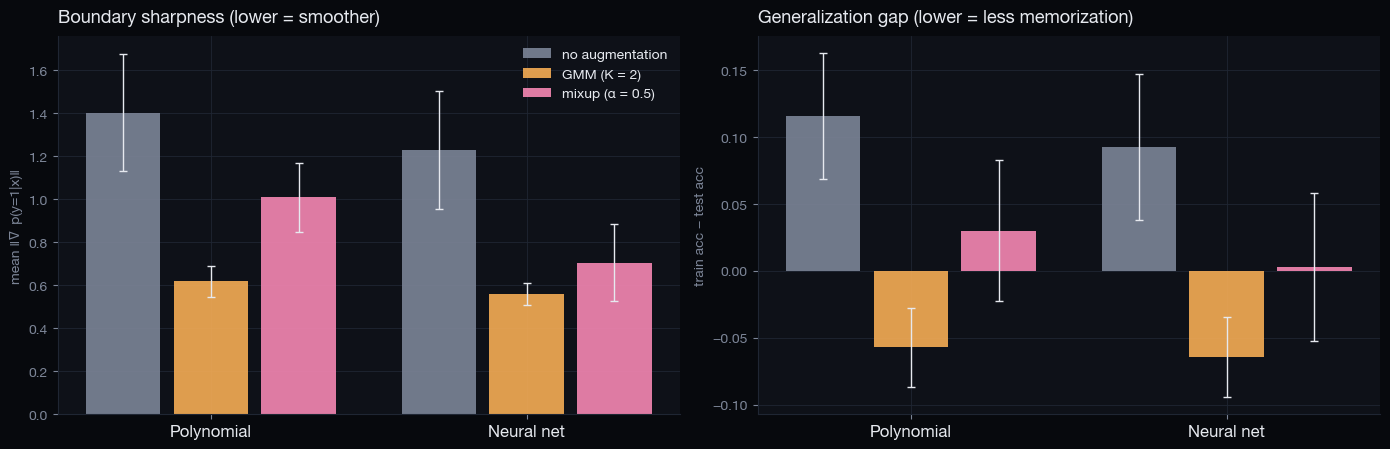

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (key, title, ylab) in zip(axes, [("grad", "Boundary sharpness (lower = smoother)", "mean ‖∇ₓ p(y=1|x)‖"),
                                         ("gap", "Generalization gap (lower = less memorization)", "train acc − test acc")]):
    neon_chart(ax, title, "", ylab)
    for k, mk in enumerate(MODELS):
        for j, ak in enumerate(AUG):
            r = RES[ak][mk]; v = (r["train"] - r["test"]) if key == "gap" else r["grad"]
            ax.bar(k * 3.6 + j, v.mean(), width=0.85, color=MCOL[ak], alpha=0.9, label=LABEL[ak] if k == 0 else None)
            ax.errorbar(k * 3.6 + j, v.mean(), yerr=v.std(), color=TXT, capsize=3, lw=1)
    ax.set_xticks([1, 4.6]); ax.set_xticklabels([MODELS[mk]["name"] for mk in MODELS], color=TXT, fontsize=12)
axes[0].legend(fontsize=10); plt.tight_layout(); plt.show()

Both augmentations cut the sharpness of the boundary and the gap between train and test: the models no longer bend around single points.

## 7. Watching it happen: training step by step

The animation **replays the exact training of §5** — same models, same subset, same augmented samples — stopping it after more and more optimizer steps:
- **Polynomial**: logistic regression fitted with L‑BFGS, one frame = number of iterations (`max_iter`);
- **Neural net**: Adam, one frame = number of epochs (`max_iter`). Like in §5, the net stops by itself once its training loss stops improving, so some runs freeze before the end.

The last frame is therefore identical to the figure of §5. Watch the curves: **without augmentation, accuracy peaks early and then falls** as the model starts memorizing the ✕. With augmentation the fall is smaller and the model ends higher.

(With augmentation an Adam epoch contains 21× more points, so the augmented nets need fewer epochs.)

Output: `animations/training_epochs.mp4` (for slides) and `animations/training_epochs.gif`.

In [38]:
FRAME_STEPS = sorted(set(np.unique(np.round(np.geomspace(1, 3000, 55)).astype(int))))
MAX_STEP = FRAME_STEPS[-1]

def aug_set(ak):
    f, kw = AUG[ak]
    if f is None: return X_tr, y_tr, None, None
    Xa, ya = f(X_tr, y_tr, np.random.default_rng(1000 + REP), **kw)   # same samples as the evaluation and the figure of §5
    return np.vstack([X_tr, Xa]), np.r_[y_tr, ya], Xa, ya

def replay(mk, ak):
    X, y, Xa, ya = aug_set(ak); frames = {}
    for k in FRAME_STEPS:
        if mk == "poly":
            m = make_pipeline(PolynomialFeatures(9), StandardScaler(), LogisticRegression(C=1e4, max_iter=k)).fit(X, y)
        else:
            m = MLPClassifier(hidden_layer_sizes=(64, 64), alpha=1e-5, max_iter=k, tol=1e-6, random_state=0).fit(X, y)
        frames[k] = dict(p=m.predict_proba(GRID)[:, 1].reshape(_gx.shape), acc=m.score(X_te, y_te), train=m.score(X_tr, y_tr), Xa=Xa, ya=ya)
    return frames

RUNS = {(mk, ak): replay(mk, ak) for mk in MODELS for ak in AUG}
for (mk, ak), fr in RUNS.items():
    accs = [fr[k]["acc"] for k in FRAME_STEPS]; best = int(np.argmax(accs))
    print(f"{MODELS[mk]['name']:12s} {LABEL[ak]:18s} best {accs[best]:.1%} at step {FRAME_STEPS[best]:>4d} · final {accs[-1]:.1%}")
STEP_NAME = {"poly": "iter", "nn": "epoch"}

Polynomial   no augmentation    best 89.6% at step   47 · final 84.0%
Polynomial   GMM (K = 2)        best 94.1% at step  241 · final 94.0%
Polynomial   mixup (α = 0.5)    best 88.3% at step  280 · final 87.1%
Neural net   no augmentation    best 93.8% at step  376 · final 85.3%
Neural net   GMM (K = 2)        best 93.7% at step   99 · final 93.6%
Neural net   mixup (α = 0.5)    best 92.0% at step  115 · final 90.0%


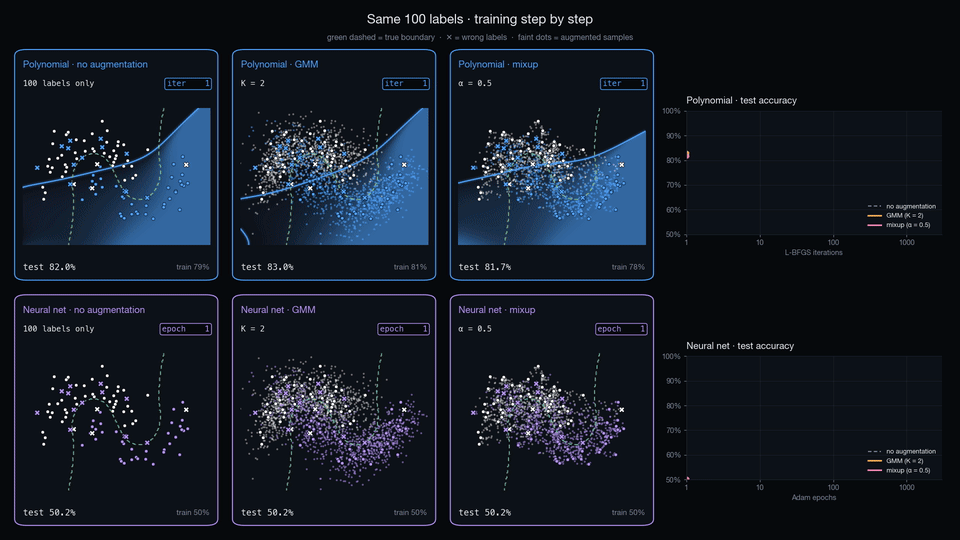

In [39]:
_W = 3 * 3.9 + 4 * 0.28 + 5.6                                         # figure width (inches); height chosen for exact 16:9
fig, P, (W, H) = panel_grid(2, 3, [COL["poly"]] * 3 + [COL["nn"]] * 3, pw=3.9, ph=(_W * 9 / 16 - 1.51) / 2, aspect=ASP, extra_right=5.6,
                            title=f"Same {N_TRAIN} labels · training step by step",
                            subtitle="green dashed = true boundary  ·  ✕ = wrong labels  ·  faint dots = augmented samples")
for r, mk in enumerate(MODELS):
    for c, ak in enumerate(AUG):
        P[r * 3 + c].set(title=f"{MODELS[mk]['name']} · {LABEL[ak].split(' (')[0]}", formula=TAG[ak] if ak != "none" else f"{N_TRAIN} labels only")
CURVES = {}
for r, mk in enumerate(MODELS):
    y0 = P[r * 3].ax.get_position().y0
    ax = fig.add_axes([(W - 5.25) / W, y0 + 0.02, 4.9 / W, P[r * 3].ax.get_position().height * 0.9])
    neon_chart(ax, f"{MODELS[mk]['name']} · test accuracy", "L-BFGS iterations" if mk == "poly" else "Adam epochs")
    ax.set_xscale("log"); ax.set_xlim(1, MAX_STEP); ax.set_ylim(0.5, 1.0); ax.minorticks_off()
    ax.set_xticks([1, 10, 100, 1000]); ax.set_xticklabels(["1", "10", "100", "1000"])
    ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0]); ax.set_yticklabels(["50%", "60%", "70%", "80%", "90%", "100%"])
    lines = {ak: ax.plot([], [], color=MCOL[ak], lw=2.2 if ak != "none" else 1.6, ls="-" if ak != "none" else (0, (3, 2)), label=LABEL[ak])[0] for ak in AUG}
    dots = {ak: ax.plot([], [], "o", color=MCOL[ak], ms=6)[0] for ak in AUG}
    ax.legend(loc="lower right", fontsize=9); CURVES[mk] = (lines, dots)

def draw_frame(ep):
    for r, mk in enumerate(MODELS):
        for c, ak in enumerate(AUG):
            p_ = P[r * 3 + c]; fr = RUNS[(mk, ak)][ep]; ax = p_.ax; ax.clear(); ax.set_facecolor(PANEL)
            ax.imshow(fr["p"], extent=(*XL, *YL), origin="lower", cmap=region_cmap(COL[mk]), vmin=0, vmax=1, alpha=0.6, interpolation="bilinear", aspect="auto")
            for lw, a in [(7, 0.08), (4, 0.18), (1.6, 1.0)]:
                ax.contour(_gx, _gy, fr["p"], levels=[0.5], colors=[COL[mk]], linewidths=lw, alpha=a)
            draw_true(ax)
            if fr["Xa"] is not None:
                ax.scatter(*fr["Xa"][fr["ya"] == 0].T, s=7, c="white", alpha=0.4, lw=0); ax.scatter(*fr["Xa"][fr["ya"] == 1].T, s=7, c=COL[mk], alpha=0.55, lw=0)
            draw_points(ax, X_tr, y_tr, COL[mk], s=22); clean(ax)
            p_.set(tag=f"{STEP_NAME[mk]} {ep:>4d}", foot_l=f"test {fr['acc']:.1%}", foot_r=f"train {fr['train']:.0%}")
        lines, dots = CURVES[mk]
        for ak in AUG:
            ks = [k for k in FRAME_STEPS if k <= ep]; cv = [RUNS[(mk, ak)][k]["acc"] for k in ks]
            lines[ak].set_data(ks, cv); dots[ak].set_data([ep], [cv[-1]])
    return []

frames = FRAME_STEPS + [FRAME_STEPS[-1]] * 16                       # pause on the last frame
anim = animation.FuncAnimation(fig, draw_frame, frames=frames, blit=False)
if animation.writers.is_available("ffmpeg"):
    fig.set_dpi(1920 / W)                                             # full-HD video for the slides
    anim.save("animations/training_epochs.mp4", writer=animation.FFMpegWriter(fps=10, bitrate=7000, extra_args=["-pix_fmt", "yuv420p"]))
    os.system('ffmpeg -loglevel error -y -i animations/training_epochs.mp4 -vf "fps=10,scale=960:-1:flags=lanczos,split[a][b];'
              '[a]palettegen[p];[b][p]paletteuse" animations/training_epochs.gif')
else:                                                                 # no ffmpeg (e.g. a fresh Mac): GIF only
    fig.set_dpi(960 / W)
    anim.save("animations/training_epochs.gif", writer=animation.PillowWriter(fps=10))
plt.close(fig)
display(Image(filename="animations/training_epochs.gif"))

**What to look at while it plays**
- **First steps**: all runs learn the coarse shape of the moons; at this point no‑augmentation is often at its best.
- **Later**: without DA the boundary starts chasing the ✕ — train accuracy climbs to 100 % and test accuracy *falls* (dashed curve). With GMM or mixup the augmented samples outvote the lies: the boundary stays smoother and closer to the green line.
- Take‑away: without augmentation the only defence is to stop at the right moment (early stopping, which needs a validation set); augmentation makes the **fully trained** model better.

## 8. Property 3 — Invariance

A second toy problem makes invariance explicit: **two concentric rings**. The label depends only on the radius, so it is **invariant to rotation**. Here the subset lies in a different way: all 30 labels come from a **single quadrant** (think: all labelled record pairs come from one data source).

- $T_{\text{rot}}$: random rotation — label‑preserving by construction → teaches the invariance;
- $T_{\text{scale}}$: random rescaling — looks harmless, but it moves points across the radius threshold → **not** label‑preserving.

A GMM or mixup cannot help here: they only fill in the region the data come from. Invariance brings **prior knowledge** that is not in the data.

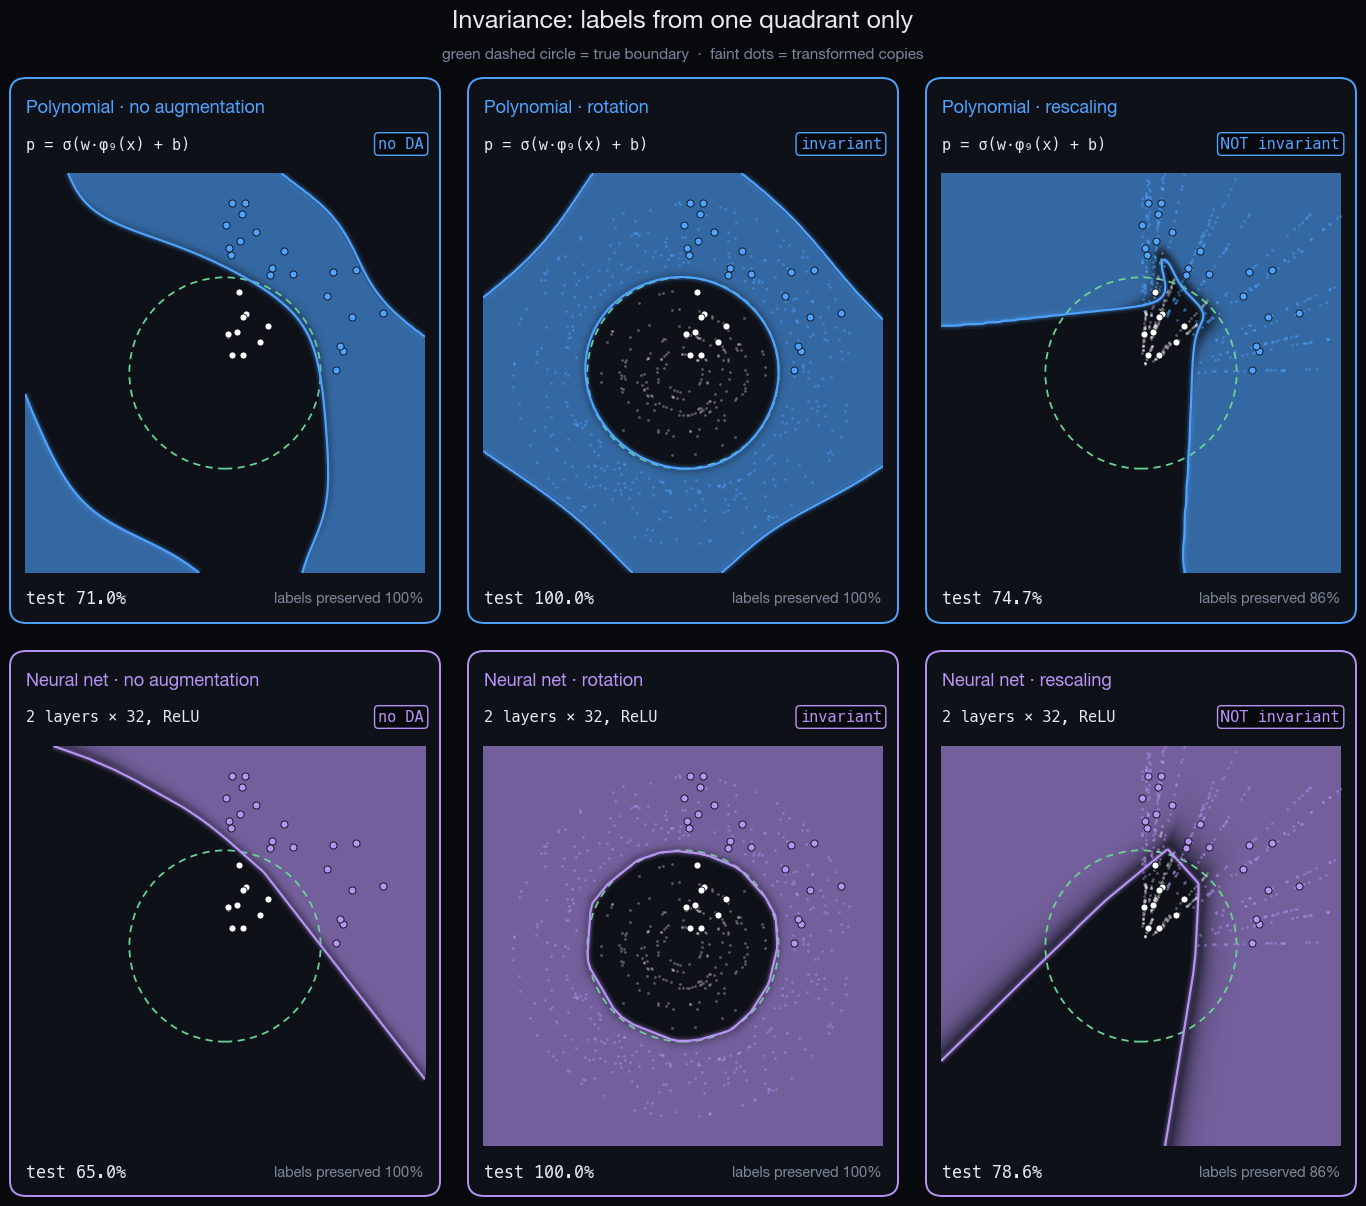

In [40]:
R_SPLIT, RLIM = 0.55, (-1.15, 1.15)
_rx, _ry = np.meshgrid(np.linspace(*RLIM, 230), np.linspace(*RLIM, 230)); RGRID = np.c_[_rx.ravel(), _ry.ravel()]

def make_rings(n, seed=0, sector=None):
    rng = np.random.default_rng(seed); y = rng.integers(0, 2, n)
    r = np.where(y == 0, rng.uniform(0.1, 0.5, n), rng.uniform(0.6, 1.0, n))
    a = rng.uniform(0, 2 * np.pi, n) if sector is None else rng.uniform(*sector, n)
    return np.c_[r * np.cos(a), r * np.sin(a)], y

ring_oracle = lambda X: (np.linalg.norm(X, axis=1) > R_SPLIT).astype(int)

def T_rotation(X, y, rng, m=20):
    a = rng.uniform(0, 2 * np.pi, len(X) * m); Xr = np.repeat(X, m, axis=0); c, s = np.cos(a), np.sin(a)
    return np.c_[c * Xr[:, 0] - s * Xr[:, 1], s * Xr[:, 0] + c * Xr[:, 1]], np.repeat(y, m)

def T_scale(X, y, rng, m=20):
    return np.repeat(X, m, axis=0) * rng.uniform(0.5, 1.6, len(X) * m)[:, None], np.repeat(y, m)

Xr_tr, yr_tr = make_rings(30, seed=0, sector=(0, np.pi / 2)); Xr_te, yr_te = make_rings(3000, seed=99)
TRANSF = [("no augmentation", None, "no DA"), ("rotation", T_rotation, "invariant"), ("rescaling", T_scale, "NOT invariant")]
fig, P, _ = panel_grid(2, 3, [COL["poly"]] * 3 + [COL["nn"]] * 3, title="Invariance: labels from one quadrant only",
                       subtitle="green dashed circle = true boundary  ·  faint dots = transformed copies")
RING_RES = {}
for r, mk in enumerate(MODELS):
    for c, (tname, T, tag) in enumerate(TRANSF):
        p_ = P[r * 3 + c]; ax = p_.ax; ax.set_facecolor(PANEL)
        if T is None: Xa = ya = None; m = MODELS[mk]["make"]().fit(Xr_tr, yr_tr); agree = 1.0
        else:
            Xa, ya = T(Xr_tr, yr_tr, np.random.default_rng(0)); agree = (ring_oracle(Xa) == ya).mean()
            m = MODELS[mk]["make"]().fit(np.vstack([Xr_tr, Xa]), np.r_[yr_tr, ya])
        pr = m.predict_proba(RGRID)[:, 1].reshape(_rx.shape)
        ax.imshow(pr, extent=(*RLIM, *RLIM), origin="lower", cmap=region_cmap(COL[mk]), vmin=0, vmax=1, alpha=0.6, aspect="auto")
        for lw, a in [(7, 0.08), (4, 0.18), (1.6, 1.0)]: ax.contour(_rx, _ry, pr, levels=[0.5], colors=[COL[mk]], linewidths=lw, alpha=a)
        ax.add_patch(Circle((0, 0), R_SPLIT, fill=False, ls=(0, (4, 3)), color=TRUE_C, lw=1.3))
        if Xa is not None:
            ax.scatter(*Xa[ya == 0].T, s=4, c="white", alpha=0.3, lw=0); ax.scatter(*Xa[ya == 1].T, s=4, c=COL[mk], alpha=0.45, lw=0)
        ax.scatter(*Xr_tr[yr_tr == 0].T, s=26, c="white", edgecolors=BG, linewidths=0.6, zorder=4)
        ax.scatter(*Xr_tr[yr_tr == 1].T, s=26, c=COL[mk], edgecolors=BG, linewidths=0.6, zorder=4)
        ax.set(xlim=RLIM, ylim=RLIM, xticks=[], yticks=[], aspect="equal")
        for s in ax.spines.values(): s.set_visible(False)
        acc = m.score(Xr_te, yr_te); RING_RES[(mk, tname)] = (acc, agree)
        p_.set(title=f"{MODELS[mk]['name']} · {tname}", formula=MODELS[mk]["formula"], tag=tag,
               foot_l=f"test {acc:.1%}", foot_r=f"labels preserved {agree:.0%}")
plt.show()

Rotation transfers what was learned in one quadrant to the whole plane: the model learns to **ignore the angle** — exactly what $T$ changes. Rescaling changes the very thing the label depends on (the radius): it injects label noise instead of knowledge.

In ER the same logic holds: abbreviating a first name, swapping token order or dropping a middle initial should not change *match / non‑match*; changing the house number in an address might.

## 9. Summary

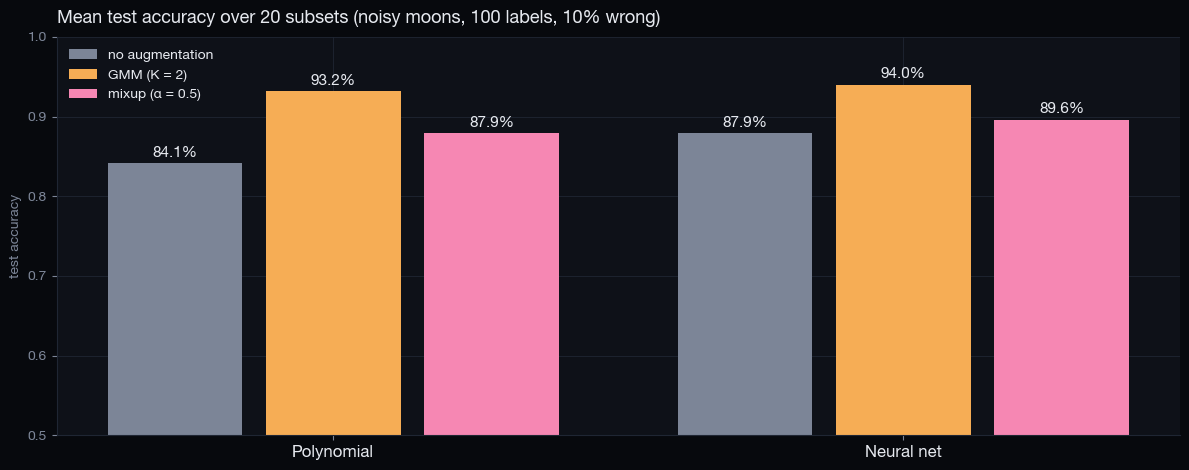

Rings (one quadrant, 30 labels)    Polynomial   Neural net
no augmentation                         71.0%        65.0%
rotation                               100.0%       100.0%
rescaling                               74.7%        78.6%


In [41]:
fig, ax = plt.subplots(figsize=(12, 4.8)); neon_chart(ax, f"Mean test accuracy over {len(EVAL_SEEDS)} subsets (noisy moons, {N_TRAIN} labels, {FLIP:.0%} wrong)", "", "test accuracy")
for k, mk in enumerate(MODELS):
    for j, ak in enumerate(AUG):
        v = RES[ak][mk]["test"]; x = k * 3.6 + j
        ax.bar(x, v.mean(), width=0.85, color=MCOL[ak], label=LABEL[ak] if k == 0 else None)
        ax.text(x, v.mean() + 0.008, f"{v.mean():.1%}", ha="center", color=TXT, fontsize=11, fontweight="bold")
ax.set_ylim(0.5, 1.0); ax.set_xticks([1, 4.6]); ax.set_xticklabels([MODELS[mk]["name"] for mk in MODELS], color=TXT, fontsize=12)
ax.legend(fontsize=10, loc="upper left"); plt.tight_layout(); plt.show()

print(f"{'Rings (one quadrant, 30 labels)':32s} " + " ".join(f"{MODELS[mk]['name']:>12s}" for mk in MODELS))
for tname, _, _ in TRANSF:
    print(f"{tname:32s} " + " ".join(f"{RING_RES[(mk, tname)][0]:12.1%}" for mk in MODELS))

In [42]:
display(Markdown(f"""**What to remember**

| Property | What we saw |
|---|---|
| **VRM** | A smooth vicinity (a coarse class‑wise GMM, or mixup) replaces {N_TRAIN} untrustworthy points with a distribution: isolated wrong labels are outvoted and test accuracy rises for both models. |
| **Regularization** | Augmentation lowers the input‑gradient norm and the train–test gap: the models stop memorizing the lies. |
| **Invariance** | A label‑preserving $T$ (rotation) carries knowledge to regions we have no labels for; a non‑preserving $T$ (rescaling) only adds label noise. |
| **Label preservation** | The constraint behind all three: a vicinity that is too fine (large K) reproduces the noise; a transformation that changes what the label depends on breaks it. |"""))

**What to remember**

| Property | What we saw |
|---|---|
| **VRM** | A smooth vicinity (a coarse class‑wise GMM, or mixup) replaces 100 untrustworthy points with a distribution: isolated wrong labels are outvoted and test accuracy rises for both models. |
| **Regularization** | Augmentation lowers the input‑gradient norm and the train–test gap: the models stop memorizing the lies. |
| **Invariance** | A label‑preserving $T$ (rotation) carries knowledge to regions we have no labels for; a non‑preserving $T$ (rescaling) only adds label noise. |
| **Label preservation** | The constraint behind all three: a vicinity that is too fine (large K) reproduces the noise; a transformation that changes what the label depends on breaks it. |